In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({ 
    "text.usetex": True,
    "font.family": "Times New Roman",
    "font.size": 12
})

In [ ]:
csv_dir_fusion_algs = './visualizations/adjacency_matrix_fusion_algs.csv'
csv_dir_fusion_LLMs = './visualizations/adjacency_matrix_fusion_LLMs.csv'

df_fusion_algs = pd.read_csv(csv_dir_fusion_algs, index_col=0)
df_fusion_LLMs = pd.read_csv(csv_dir_fusion_LLMs, index_col=0)

print(df_fusion_algs)
print(df_fusion_LLMs)

      Mo  Ni  Si  P  N  Cr  PP  NaCl  CPT
Mo     0   1   2  3  2   0   1     0    3
Ni     0   0   1  0  2   0   0     0    0
Si     0   1   0  0  0   0   1     0    0
P      0   0   0  0  1   0   0     0    2
N      1   1   0  1  0   0   0     0    0
Cr     1   1   0  2  1   0   2     0    0
PP     1   1   3  0  2   2   0     0    0
NaCl   0   0   0  0  0   0   1     0    3
CPT    0   0   0  1  0   0   0     0    0
      Mo  Ni  Si  P  N  Cr  PP  NaCl  CPT
Mo     0   0   0  0  0   1   2     0    3
Ni     0   0   0  0  0   0   1     0    2
Si     0   0   0  0  0   0   2     0    3
P      0   0   0  0  0   0   2     0    3
N      0   0   0  0  0   1   2     0    3
Cr     0   0   0  0  0   0   2     0    3
PP     0   0   0  0  0   0   0     0    2
NaCl   0   0   0  0  0   0   2     0    3
CPT    0   0   0  0  0   0   1     0    0


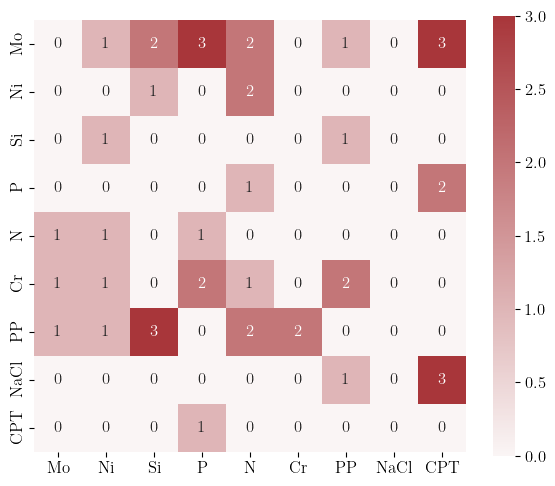

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

plt.figure(figsize=(6, 5))
my_cmap1 = mcolors.LinearSegmentedColormap.from_list("my_red", ["#faf5f5", "#A8363A"])
sns.heatmap(df_fusion_algs, annot=True, cmap=my_cmap1, cbar=True, linewidths=0, square=True)
plt.tight_layout()
plt.show()

In [ ]:
df_fusion_algs_01 = df_fusion_algs.map(lambda x: 1 if x > 0 else 0) 
print(df_fusion_algs_01)

      Mo  Ni  Si  P  N  Cr  PP  NaCl  CPT
Mo     0   1   1  1  1   0   1     0    1
Ni     0   0   1  0  1   0   0     0    0
Si     0   1   0  0  0   0   1     0    0
P      0   0   0  0  1   0   0     0    1
N      1   1   0  1  0   0   0     0    0
Cr     1   1   0  1  1   0   1     0    0
PP     1   1   1  0  1   1   0     0    0
NaCl   0   0   0  0  0   0   1     0    1
CPT    0   0   0  1  0   0   0     0    0


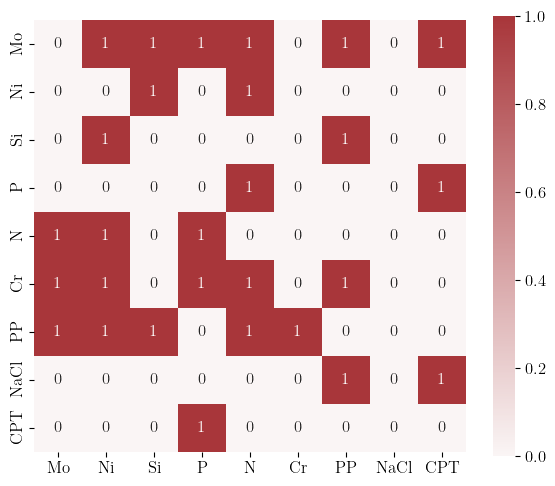

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
my_cmap1 = mcolors.LinearSegmentedColormap.from_list("my_red", ["#faf5f5", "#A8363A"])
sns.heatmap(df_fusion_algs_01, annot=True, cmap=my_cmap1, cbar=True, linewidths=0, square=True)
plt.tight_layout()
plt.show()

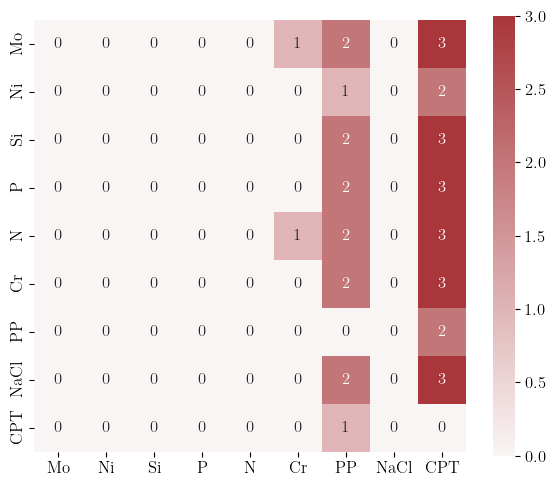

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

plt.figure(figsize=(6, 5))
my_cmap1 = mcolors.LinearSegmentedColormap.from_list("my_red", ["#faf5f5", "#A8363A"])
sns.heatmap(df_fusion_LLMs, annot=True, cmap=my_cmap1, cbar=True, linewidths=0, square=True)
plt.tight_layout()
plt.show()

In [ ]:
weight_algs = 1-89 / (89+104)
weight_LLMs = 1-104 / (89+104)

print(f"weight of data-driven methods: {weight_algs} \n weights of LLMs: {weight_LLMs}")

In [ ]:
df_fusion_weighted = df_fusion_algs * weight_algs + df_fusion_LLMs * weight_LLMs
print(df_fusion_weighted)

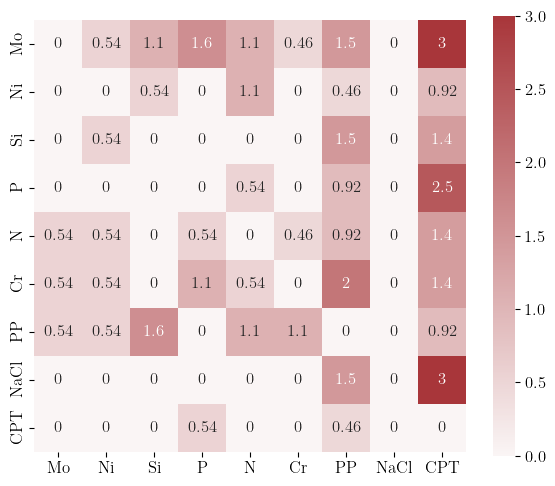

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

my_cmap1 = mcolors.LinearSegmentedColormap.from_list("my_red", ["#faf5f5", "#A8363A"])
plt.figure(figsize=(6, 5))
sns.heatmap(df_fusion_weighted, annot=True, cmap=my_cmap1, cbar=True, linewidths=0, square=True)
plt.tight_layout()
plt.show()

In [ ]:
df_fusion_weighted_thresh = df_fusion_weighted.where(df_fusion_weighted > 1.0, 0)

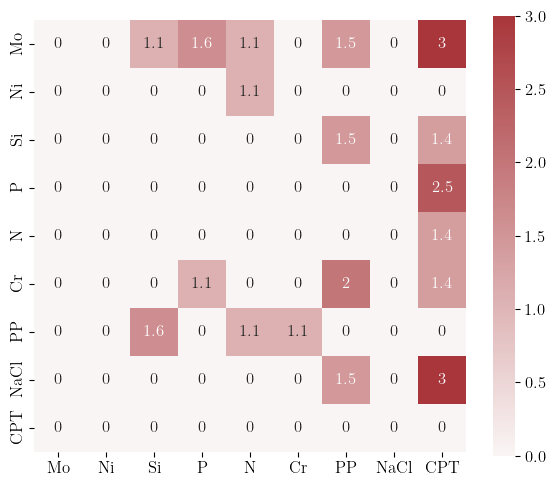

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
my_cmap1 = mcolors.LinearSegmentedColormap.from_list("my_red", ["#faf5f5", "#A8363A"])
sns.heatmap(df_fusion_weighted_thresh, annot=True, cmap=my_cmap1, cbar=True, linewidths=0, square=True)
plt.tight_layout()
plt.show()

In [ ]:
df_new = df_fusion_weighted_thresh.copy()
df_new.loc['Si', 'PP'] = 0
df_new.loc['PP', 'Si'] = 0
df_new.loc['Cr', 'PP'] = 0
df_new.loc['PP', 'Cr'] = 0
df_new

,Mo,Ni,Si,P,N,Cr,PP,NaCl,CPT
Mo,0.0,0.0,1.07772,1.61658,1.07772,0.0,1.46114,0.0,3.00000
Ni,0.0,0.0,0.00000,0.00000,1.07772,0.0,0.00000,0.0,0.00000
Si,0.0,0.0,0.00000,0.00000,0.00000,0.0,0.00000,0.0,1.38342
P,0.0,0.0,0.00000,0.00000,0.00000,0.0,0.00000,0.0,2.46114
N,0.0,0.0,0.00000,0.00000,0.00000,0.0,0.00000,0.0,1.38342
Cr,0.0,0.0,0.00000,1.07772,0.00000,0.0,0.00000,0.0,1.38342
PP,0.0,0.0,0.00000,0.00000,1.07772,0.0,0.00000,0.0,0.00000
NaCl,0.0,0.0,0.00000,0.00000,0.00000,0.0,1.46114,0.0,3.00000
CPT,0.0,0.0,0.00000,0.00000,0.00000,0.0,0.00000,0.0,0.00000


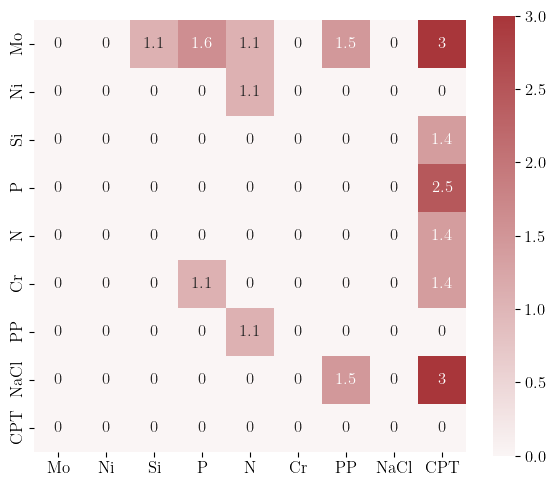

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
my_cmap1 = mcolors.LinearSegmentedColormap.from_list("my_red", ["#faf5f5", "#A8363A"])
sns.heatmap(df_new, annot=True, cmap=my_cmap1, cbar=True, linewidths=0, square=True)
plt.tight_layout()
plt.show()

In [ ]:
df_new_01 = df_new.applymap(lambda x: 1 if x > 0 else 0) 
print(df_new_01)

      Mo  Ni  Si  P  N  Cr  PP  NaCl  CPT
Mo     0   0   1  1  1   0   1     0    1
Ni     0   0   0  0  1   0   0     0    0
Si     0   0   0  0  0   0   0     0    1
P      0   0   0  0  0   0   0     0    1
N      0   0   0  0  0   0   0     0    1
Cr     0   0   0  1  0   0   0     0    1
PP     0   0   0  0  1   0   0     0    0
NaCl   0   0   0  0  0   0   1     0    1
CPT    0   0   0  0  0   0   0     0    0


C:\Users\cjq\AppData\Local\Temp\ipykernel_70060\3472489259.py:5: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_new_01 = df_new.applymap(lambda x: 1 if x > 0 else 0)


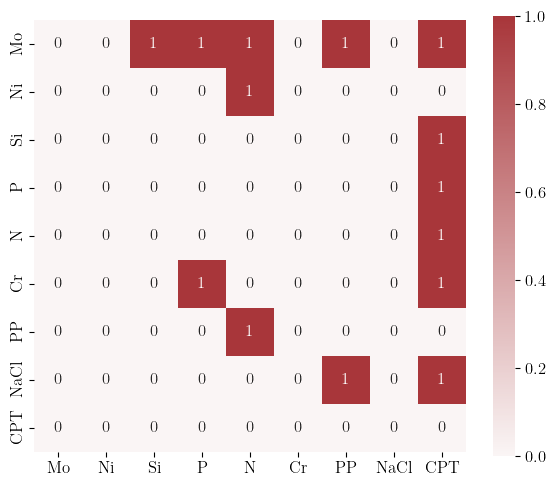

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
my_cmap1 = mcolors.LinearSegmentedColormap.from_list("my_red", ["#faf5f5", "#A8363A"])
sns.heatmap(df_new_01, annot=True, cmap=my_cmap1, cbar=True, linewidths=0, square=True)
plt.tight_layout()
plt.show()

In [ ]:
df_fusion_weighted_thresh_binary = df_fusion_weighted_thresh.applymap(lambda x: 1 if x > 0 else 0)
print(df_fusion_weighted_thresh_binary)

      Mo  Ni  Si  P  N  Cr  PP  NaCl  CPT
Mo     0   0   1  1  1   0   1     0    1
Ni     0   0   0  0  1   0   0     0    0
Si     0   0   0  0  0   0   1     0    1
P      0   0   0  0  0   0   0     0    1
N      0   0   0  0  0   0   0     0    1
Cr     0   0   0  1  0   0   1     0    1
PP     0   0   1  0  1   1   0     0    0
NaCl   0   0   0  0  0   0   1     0    1
CPT    0   0   0  0  0   0   0     0    0


C:\Users\cjq\AppData\Local\Temp\ipykernel_44280\1623542414.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_fusion_weighted_thresh_binary = df_fusion_weighted_thresh.applymap(lambda x: 1 if x > 0 else 0)


In [10]:
df_binary = df_fusion_weighted_thresh_binary

In [ ]:
causal_dict = {}

for col in df_binary.columns:
    causes = [row for row in df_binary.index if df_binary.at[row, col] != 0]
    if causes:
        causal_dict[col] = causes

print("Causal dictionary (effect: [causes]):")
for effect, causes in causal_dict.items():
    print(f"{effect}: {causes}")

Causal dictionary (effect: [causes]):
Si: ['Mo', 'PP']
P: ['Mo', 'Cr']
N: ['Mo', 'Ni', 'PP']
Cr: ['PP']
PP: ['Mo', 'Si', 'Cr', 'NaCl']
CPT: ['Mo', 'Si', 'P', 'N', 'Cr', 'NaCl']


In [ ]:
model_formula_list = []
for effect, causes in causal_dict.items():
    if causes:
        causes_str = " + ".join(causes)
        formula = f"{effect} ~ {causes_str}"
        model_formula_list.append(formula)
        
for formula in model_formula_list:
    print(formula)

Si ~ Mo + PP
P ~ Mo + Cr
N ~ Mo + Ni + PP
Cr ~ PP
PP ~ Mo + Si + Cr + NaCl
CPT ~ Mo + Si + P + N + Cr + NaCl


In [ ]:
# The first step
from semopy import Model

mod = """ 
Si ~ Mo 
P ~ Mo + Cr
N ~ Mo + Ni + PP
PP ~ Mo + NaCl
CPT ~ Mo + Si + P + N + Cr + NaCl
"""
model = Model(mod)

In [ ]:
# The second step
from pandas import read_csv
data = read_csv("./CPT-graphs/treadCG/data_cpt_standard.csv")

In [15]:
data

,Co,Ti,Mo,Ni,W,Al,Si,V,Cu,P,...,roughness,temperature,time,testing_area,IT,PP,heating_rate,NaCl,NaBr,CPT
0,-0.090168,-0.21301,-0.979624,-0.058197,-0.164532,-0.157466,0.781041,-0.157466,-0.73329,1.187569,...,-0.011792,-0.821423,-0.394016,-2.399572,-0.489686,-0.685085,-0.143449,-1.057903,-0.230037,-0.804804
1,-0.090168,-0.21301,-0.979624,-0.058197,-0.164532,-0.157466,0.781041,-0.157466,-0.73329,1.187569,...,-0.011792,-0.821423,-0.394016,-2.399572,-0.489686,-0.685085,-0.143449,-1.057903,-0.230037,-0.522297
2,-0.090168,-0.21301,-0.979624,-0.058197,-0.164532,-0.157466,0.781041,-0.157466,-0.73329,1.187569,...,-0.011792,-0.821423,-0.394016,-2.399572,-0.489686,-0.685085,-0.143449,-1.057903,-0.230037,-0.718616
3,-0.090168,-0.21301,-0.979624,-0.058197,-0.164532,-0.157466,0.781041,-0.157466,-0.73329,1.187569,...,-0.011792,-0.821423,-0.394016,-2.399572,-0.489686,-0.685085,-0.143449,-1.057903,-0.230037,-0.718616
4,-0.090168,-0.21301,-0.979624,-0.058197,-0.164532,-0.157466,0.781041,-0.157466,-0.73329,1.187569,...,-0.011792,-0.821423,-0.394016,-2.399572,-0.489686,-0.685085,-0.143449,-1.057903,-0.230037,-0.263732
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
242,-0.090168,-0.21301,-0.857716,-0.603987,-0.164532,-0.157466,0.856867,-0.157466,-0.73329,1.810538,...,-0.011792,1.218432,0.830474,0.429312,-1.019250,0.360571,-0.143449,-0.137678,-0.230037,0.952484
243,-0.090168,-0.21301,-0.857716,-0.603987,-0.164532,-0.157466,0.856867,-0.157466,-0.73329,1.810538,...,-0.011792,1.181344,0.830474,0.429312,-1.019250,0.360571,-0.143449,-0.137678,-0.230037,1.167955
244,-0.090168,-0.21301,-0.979624,-0.603987,-0.164532,-0.157466,0.856867,-0.157466,-0.73329,1.810538,...,-0.011792,1.125712,0.830474,0.429312,-1.019250,0.360571,-0.143449,-0.137678,-0.230037,0.899813
245,-0.090168,-0.21301,-0.857716,-0.603987,-0.164532,-0.157466,0.856867,-0.157466,-0.73329,1.810538,...,-0.011792,1.088623,0.830474,0.429312,-1.019250,0.360571,-0.143449,-0.137678,-0.230037,0.684342


In [16]:
# The third step
model.fit(data)

SolverResult(fun=np.float64(1.5560121496282706), success=np.True_, n_it=16, x=array([-0.57323449, -0.90394626,  0.3887557 ,  0.80590983, -0.19842705,
        0.15437474,  0.68176278, -0.13775865,  0.60733035, -0.10602164,
        0.07326806,  0.1657201 , -0.13118608,  0.05041219,  0.50494224,
        0.42768616,  0.39949252,  0.57578962,  0.66888929]), message='Optimization terminated successfully', name_method='SLSQP', name_obj='MLW')

In [17]:
model.inspect()

,lval,op,rval,Estimate,Std. Err,z-value,p-value
0,Si,~,Mo,-0.573234,0.052145,-10.993165,0.000000e+00
1,P,~,Mo,-0.903946,0.047357,-19.088058,0.000000e+00
2,P,~,Cr,0.388756,0.047357,8.209107,2.220446e-16
3,N,~,Mo,0.805910,0.083810,9.615911,0.000000e+00
4,N,~,Ni,-0.198427,0.077297,-2.567082,1.025582e-02
5,N,~,PP,0.154375,0.054077,2.854705,4.307679e-03
6,PP,~,Mo,0.681763,0.051259,13.300371,0.000000e+00
7,PP,~,NaCl,-0.137759,0.051259,-2.687505,7.198794e-03
8,CPT,~,Mo,0.607330,0.103745,5.854041,4.797702e-09
9,CPT,~,Si,-0.106022,0.055283,-1.917782,5.513864e-02


In [ ]:
import semopy

stats = semopy.calc_stats(model).round(3)
print(stats.T)

                  Value
DoF              26.000
DoF Baseline     40.000
chi2            384.335
chi2 p-value      0.000
chi2 Baseline  1647.540
CFI               0.777
GFI               0.767
AGFI              0.641
NFI               0.767
TLI               0.657
RMSEA             0.237
AIC              34.888
BIC             101.566
LogLik            1.556


In [ ]:
g = semopy.semplot(model, "./fusion/fusion_CD_algs_LLMs2.pdf")  

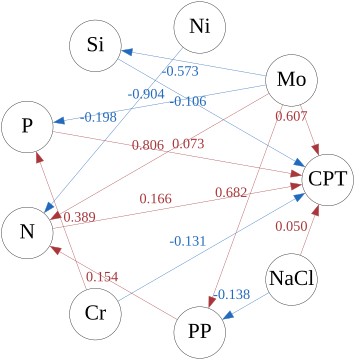

'visualizations\\CPT_graphs\\all_CPT.pdf'

In [ ]:
import graphviz
from utils.get_node_positions import get_node_positions

nodes_list = ['Mo', 'Ni', 'Si', 'P', 'N', 'Cr', 'PP', 'NaCl', 'CPT']
output_str = get_node_positions(nodes_list, radius=6)

gv_dot = f"""

//==========================================

strict digraph "DAG" {{

//------------------------------------

layout=neato; 
size="5,5";
node [shape=circle, fixedsize=true, width=2.0, height=2.0];

node [fontsize=60];
edge [fontsize=40, arrowsize=3.0];

//---------------------------------

{output_str}

//----------------------------------------------------

	Mo -> Si [label="-0.573", fontcolor="#2369BC", color="#2369BC"]
	Mo -> P [label="-0.904", fontcolor="#2369BC", color="#2369BC"]
	Cr -> P [label="0.389", fontcolor="#A8363A", color="#A8363A"]
	Mo -> N [label="0.806", fontcolor="#A8363A", color="#A8363A"]
	Ni -> N [label="-0.198", fontcolor="#2369BC", color="#2369BC"]
	PP -> N [label="0.154", fontcolor="#A8363A", color="#A8363A"]
	Mo -> PP [label="0.682", fontcolor="#A8363A", color="#A8363A"]
	NaCl -> PP [label="-0.138", fontcolor="#2369BC", color="#2369BC"]
	Mo -> CPT [label="0.607", fontcolor="#A8363A", color="#A8363A"]
	Si -> CPT [label="-0.106", fontcolor="#2369BC", color="#2369BC"]
	P -> CPT [label="0.073", fontcolor="#A8363A", color="#A8363A"]
	N -> CPT [label="0.166", fontcolor="#A8363A", color="#A8363A"]
	Cr -> CPT [label="-0.131", fontcolor="#2369BC", color="#2369BC"]
	NaCl -> CPT [label="0.050", fontcolor="#A8363A", color="#A8363A"]

//----------------------------------------------------------------

}}

//================================================================


"""

src = graphviz.Source(gv_dot)

display(src)

src.render('./visualizations/CPT_graphs/all_CPT', format='pdf')